# Create reference model with semi-supervised surgery pipeline using scANVI

In [2]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [3]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [4]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [5]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

## import un-integrated atlas:

The atlas will be integrated here, and will serve as reference in downstream mapping of new data to the atlas. We therefore call it "source_adata", as opposed to "query_adata".

In [6]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v4.h5ad")

### set labels to use for integration:

check which cells have only level 1 annotations:

In [7]:
lev1_obs = source_adata.obs.loc[source_adata.obs.ann_highest_res == 1, :].copy()
print("Number of cells with only level 1 annotation:", lev1_obs.shape[0])

Number of cells with only level 1 annotation: 7177


In [8]:
# count number of cells per original_ann_level_1 group that have no further annotations
lev1_annotations = lev1_obs.groupby("original_ann_level_1").agg({"original_ann_level_1":"count"}).rename(columns={"original_ann_level_1":"n_cells_w_only_l1_ann"})
# count total cells in each original_ann_level_1 group
lev1_annotations['total'] = source_adata.obs.groupby("original_ann_level_1").agg({"original_ann_level_1":"count"}).loc[lev1_annotations.index,"original_ann_level_1"]

In [9]:
lev1_annotations

,n_cells_w_only_l1_ann,total
original_ann_level_1,,
Endothelial,2449,49738
Epithelial,1889,281547
Immune,0,226595
Proliferating cells,1811,1811
Stroma,1028,25193


We will let all "Proliferating cells" keep their labels, and will set all other cells as "unlabeled" (since they only make up a small part of their group)

In [10]:
lev1_labeled = source_adata.obs.index[source_adata.obs.original_ann_level_1 == "Proliferating cells"]

In [11]:
lev1_unlabeled = source_adata.obs.index[[max_res == 1 and lev1label != "Proliferating cells" for max_res, lev1label in zip(source_adata.obs.ann_highest_res, source_adata.obs.original_ann_level_1)]]

In [12]:
len(lev1_labeled)

1811

In [13]:
len(lev1_unlabeled)

5366

In [14]:
# check if all labels/cells are accounted for
lev1_annotations.n_cells_w_only_l1_ann.sum() == len(lev1_labeled) + len(lev1_unlabeled)

True

Now check which cells have only up to level 2 annotations:

In [15]:
lev2_obs = source_adata.obs.loc[source_adata.obs.ann_highest_res == 2, :].copy()
print("Number of cells with only level 1/2 annotation:", lev2_obs.shape[0])

Number of cells with only level 1/2 annotation: 30315


In [16]:
# count number of cells per original_ann_level_2 group that have no further annotations
lev2_annotations = lev2_obs.groupby("original_ann_level_2").agg({"original_ann_level_2":"count"}).rename(columns={"original_ann_level_2":"n_cells_w_only_l2_ann"})
# count total cells in each original_ann_level_2 group
lev2_annotations['total'] = source_adata.obs.groupby("original_ann_level_2").agg({"original_ann_level_2":"count"}).loc[lev2_annotations.index,"original_ann_level_2"]

In [17]:
lev2_annotations

,n_cells_w_only_l2_ann,total
original_ann_level_2,,
1_Endothelial,0,2449
1_Epithelial,0,1889
1_Proliferating cells,0,1811
1_Stroma,0,1028
Airway epithelium,0,204888
Alveolar epithelium,248,67782
Blood vessels,6900,42667
Fibroblast lineage,4537,20548
Granulocytes,0,2


We will set all cells with level 2 annotations "Fibroblast lineage", "Mesothelium", "Lymphatic EC", and "Smooth Muscle" to their level 2 annotations. All other cels with only level 2 annotations will be set to unlabeled. 

In [18]:
lev2_labels_to_keep = ["Fibroblast lineage", "Mesothelium", "Lymphatic EC", "Smooth muscle"]
lev2_labeled = source_adata.obs.index[[lev2_lab in lev2_labels_to_keep for lev2_lab in source_adata.obs.original_ann_level_2]]

In [19]:
len(lev2_labeled) == lev2_annotations.loc[lev2_labels_to_keep,"total"].sum()

True

In [20]:
lev2_unlabeled = source_adata.obs.index[[max_res == 2 and lev2_lab not in lev2_labels_to_keep for max_res, lev2_lab in zip(source_adata.obs.ann_highest_res, source_adata.obs.original_ann_level_2)]]

In [21]:
len(lev2_unlabeled) == lev2_annotations.loc[~lev2_annotations.index.isin(lev2_labels_to_keep),"n_cells_w_only_l2_ann"].sum()

True

now generate scANVI labels:

In [22]:
source_adata.obs['scanvi_label'] = source_adata.obs.original_ann_level_3.tolist()
source_adata.obs.loc[lev1_labeled,'scanvi_label'] = source_adata.obs.loc[lev1_labeled, "original_ann_level_1"]
source_adata.obs.loc[lev1_unlabeled,'scanvi_label'] = "unlabeled"
source_adata.obs.loc[lev2_labeled,'scanvi_label'] = source_adata.obs.loc[lev2_labeled, "original_ann_level_2"]
source_adata.obs.loc[lev2_unlabeled,'scanvi_label'] = "unlabeled"

... storing 'scanvi_label' as categorical


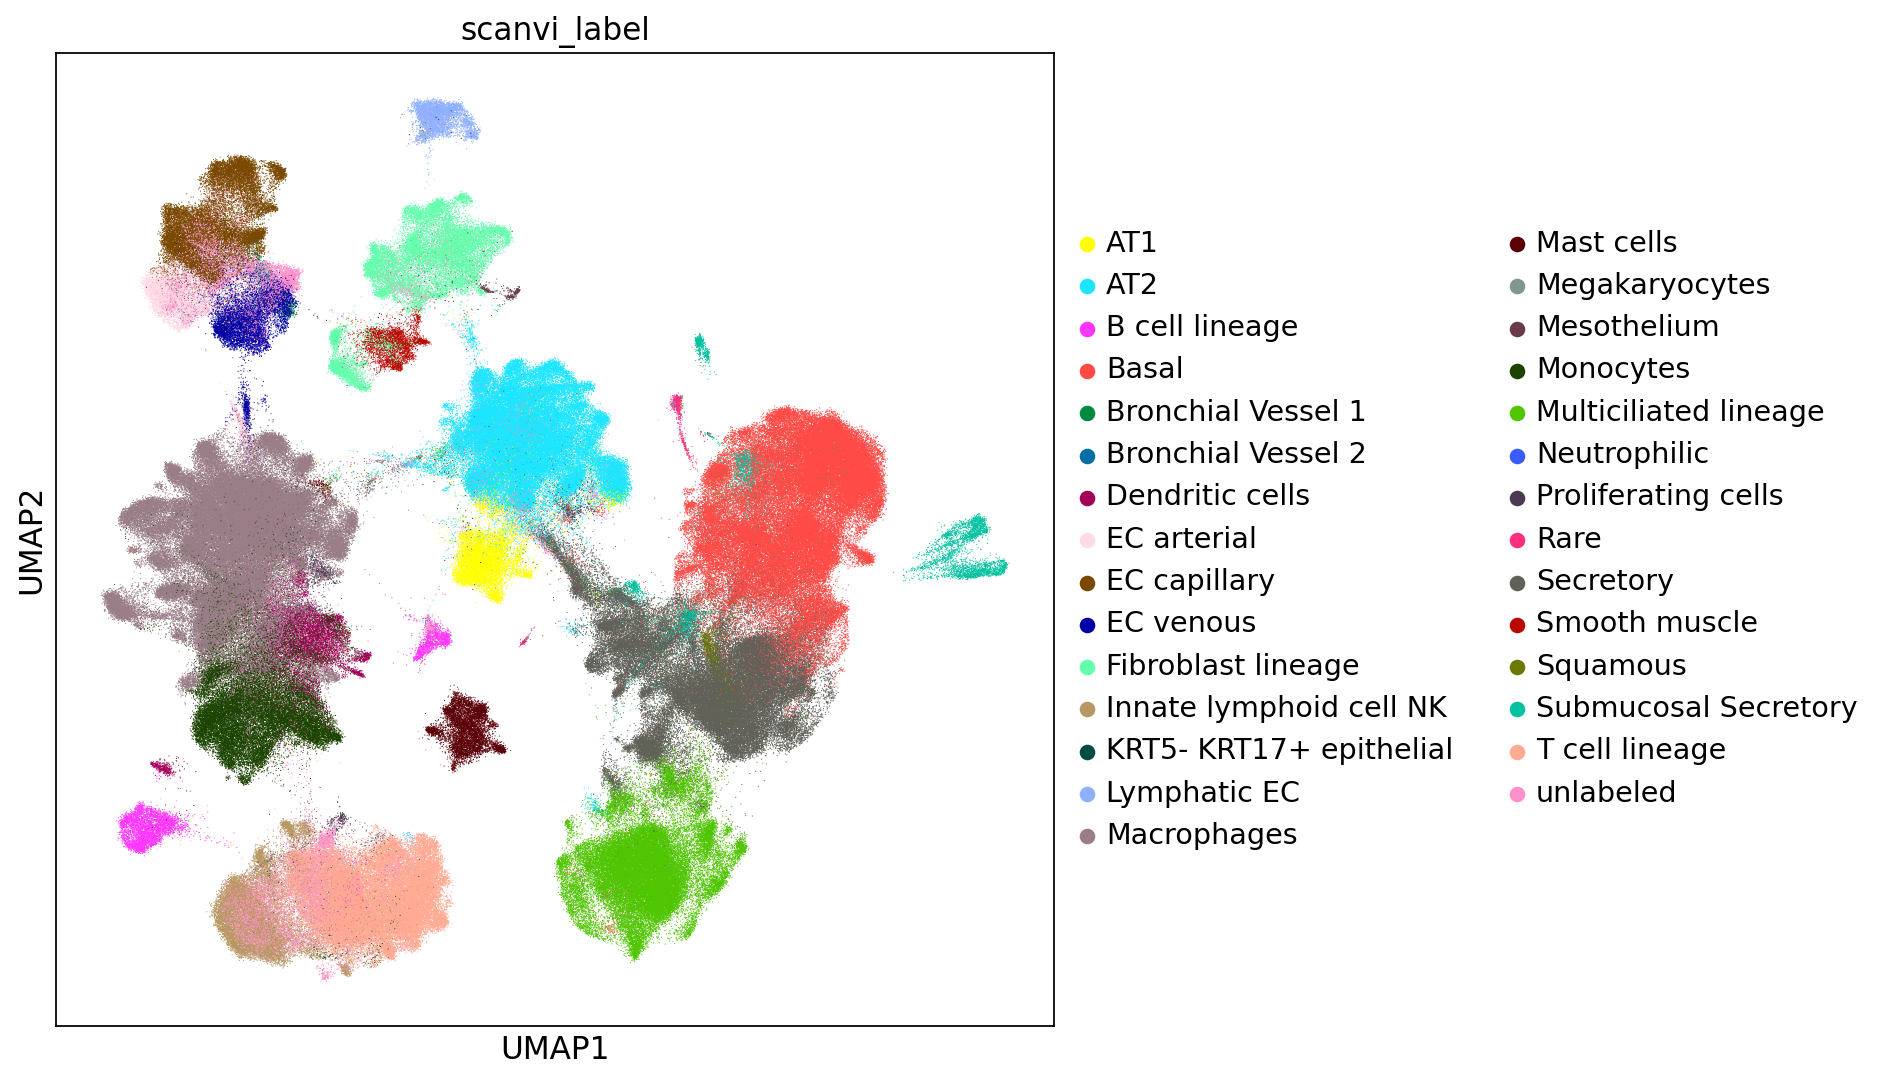

In [23]:
sc.set_figure_params(figsize=(8,8))
sc.pl.umap(source_adata,color='scanvi_label',size=1)

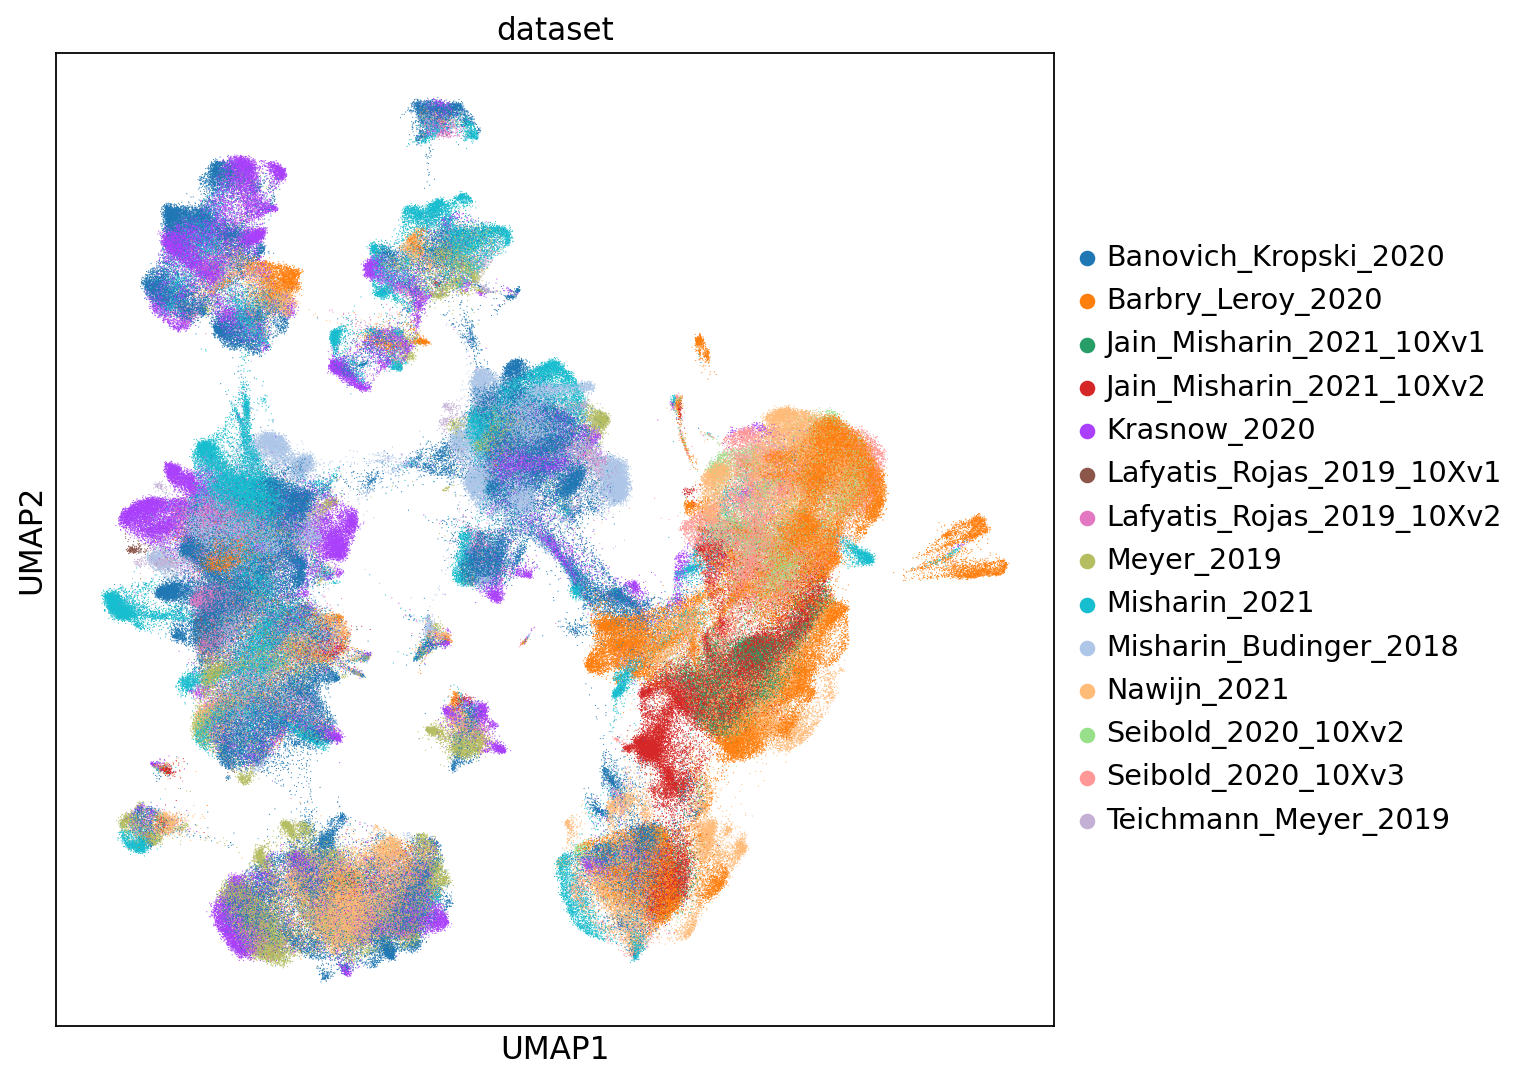

In [24]:
sc.set_figure_params(figsize=(8,8))
sc.pl.umap(source_adata,color='dataset',size=1)

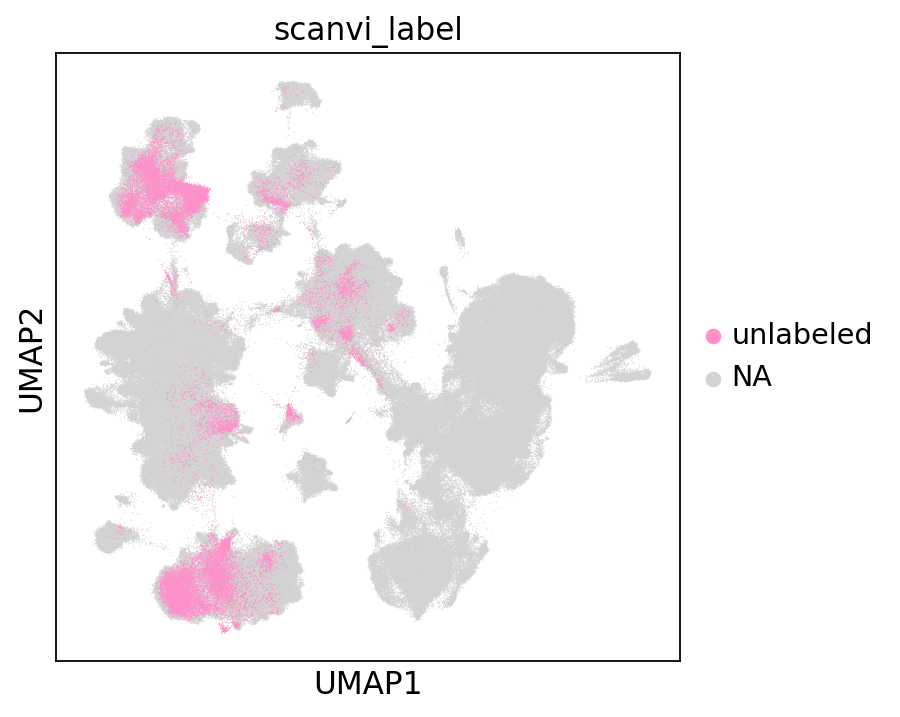

In [25]:
sc.set_figure_params(figsize=(5,5))
sc.pl.umap(source_adata,color='scanvi_label',size=1,groups=['unlabeled'])

### subset to hvgs and create raw layers

Save source_adata as new version of LCA datasets to have updated cell type labels.

In [26]:
source_adata.write("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")

subset data to highly variable genes, and make sure we have raw counts as data.

In [26]:
source_adata = source_adata[:,source_adata.var.highly_variable].copy()

In [27]:
source_adata.shape

(584884, 2000)

source_adata currently has normalized counts, so we need to use the .layers['counts'] layer to set raw.X. Also set adata.X to the counts.

In [28]:
source_adata.X = source_adata.layers['counts']
source_adata.raw = source_adata
raw = source_adata.raw.to_adata()
raw.X = source_adata.layers['counts']
source_adata.raw = raw

sanity check:

In [29]:
source_adata.raw.X[:5,:8].toarray()

array([[0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [2., 0., 0., 0., 0., 0., 0., 0.],
       [0., 2., 3., 0., 0., 0., 1., 0.]], dtype=float32)

In [30]:
source_adata.X[:5,:8].toarray()

array([[0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [2., 0., 0., 0., 0., 0., 0., 0.],
       [0., 2., 3., 0., 0., 0., 1., 0.]], dtype=float32)

In [31]:
source_adata.layers['counts'][:5,:8].toarray()

array([[0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0.],
       [2., 0., 0., 0., 0., 0., 0., 0.],
       [0., 2., 3., 0., 0., 0., 1., 0.]], dtype=float32)

### Set relevant anndata.obs labels and training length

We use parameters as provided in scArches tutorial.

In [33]:
source_adata.obs.dataset.unique().tolist()

['Misharin_Budinger_2018',
 'Krasnow_2020',
 'Seibold_2020_10Xv3',
 'Banovich_Kropski_2020',
 'Nawijn_2021',
 'Misharin_2021',
 'Seibold_2020_10Xv2',
 'Barbry_Leroy_2020',
 'Teichmann_Meyer_2019',
 'Lafyatis_Rojas_2019_10Xv1',
 'Lafyatis_Rojas_2019_10Xv2',
 'Meyer_2019',
 'Jain_Misharin_2021_10Xv2',
 'Jain_Misharin_2021_10Xv1']

In [34]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

### Create SCANVI model and train it on atlas

Denovo integration using scVI and scANVI with precalculated highly variable genes (by Lisa).

In [36]:
sca.dataset.setup_anndata(source_adata, batch_key=condition_key, labels_key=cell_type_key)

Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [37]:
scvi_model = sca.models.SCVI(
    source_adata,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

Train scVI model for the reference atlas.

In [38]:
scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

In [39]:
scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/scVI")

In [35]:
scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scVI", source_adata)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Calculate latent embedding of the reference data.

In [36]:
source_adata.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [37]:
sc.pp.neighbors(source_adata, use_rep="X_scVI")
sc.tl.leiden(source_adata)
sc.tl.umap(source_adata)

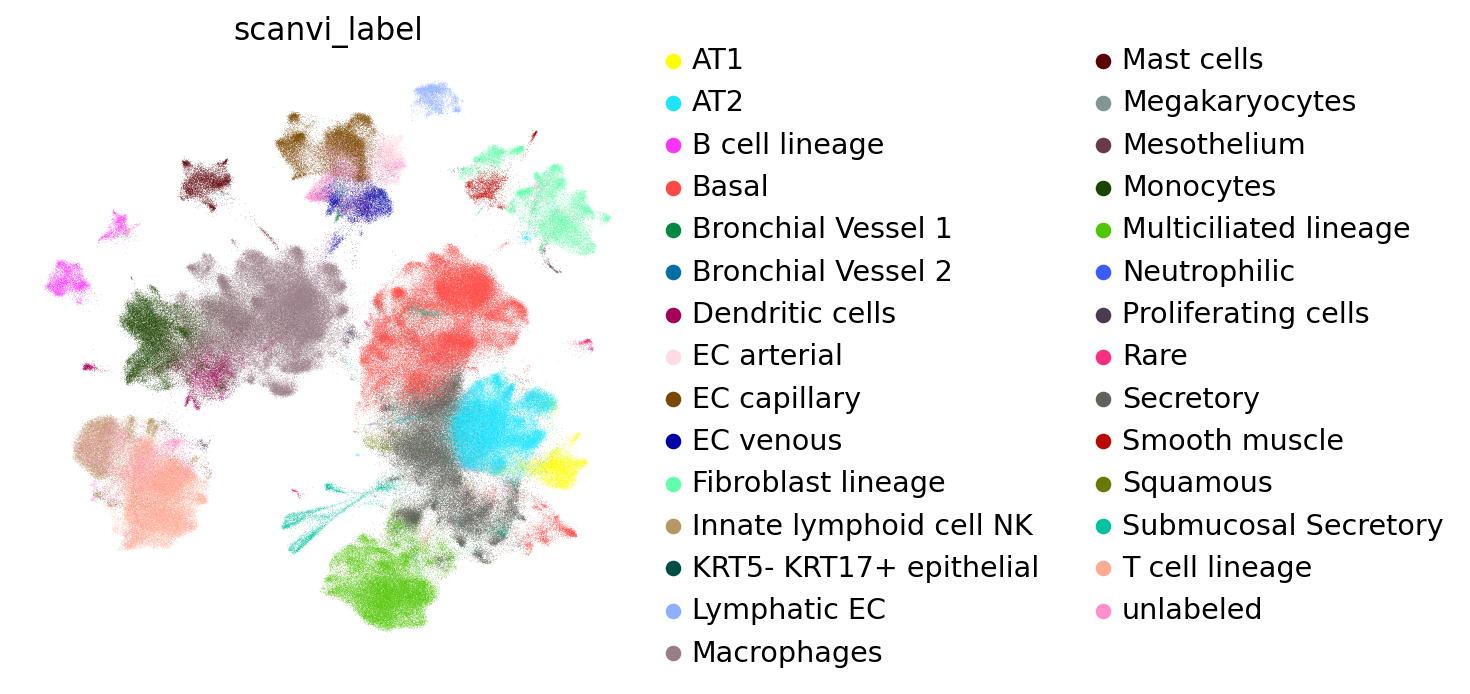

In [39]:
sc.pl.umap(source_adata, color=cell_type_key, frameon=False)

Build scANVI model ontop of scVI model. Therefore load scVI model and then train scANVI model based on it, now including cell type annotations information.

In [45]:
scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=source_adata)

In [46]:
scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

In [47]:
scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI")

In [40]:
scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", source_adata)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [41]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Labelled Indices:  560710
Unlabelled Indices:  24174


Predict cell type annotations, calculate latent embedding of integrated data.

In [42]:
source_adata.obs["C_scANVI"] = scANVI_model.predict(source_adata)
source_adata.obsm["X_scANVI"] = scANVI_model.get_latent_representation(source_adata)

In [43]:
sc.pp.neighbors(source_adata, use_rep="X_scANVI")
sc.tl.umap(source_adata)

... storing 'C_scANVI' as categorical


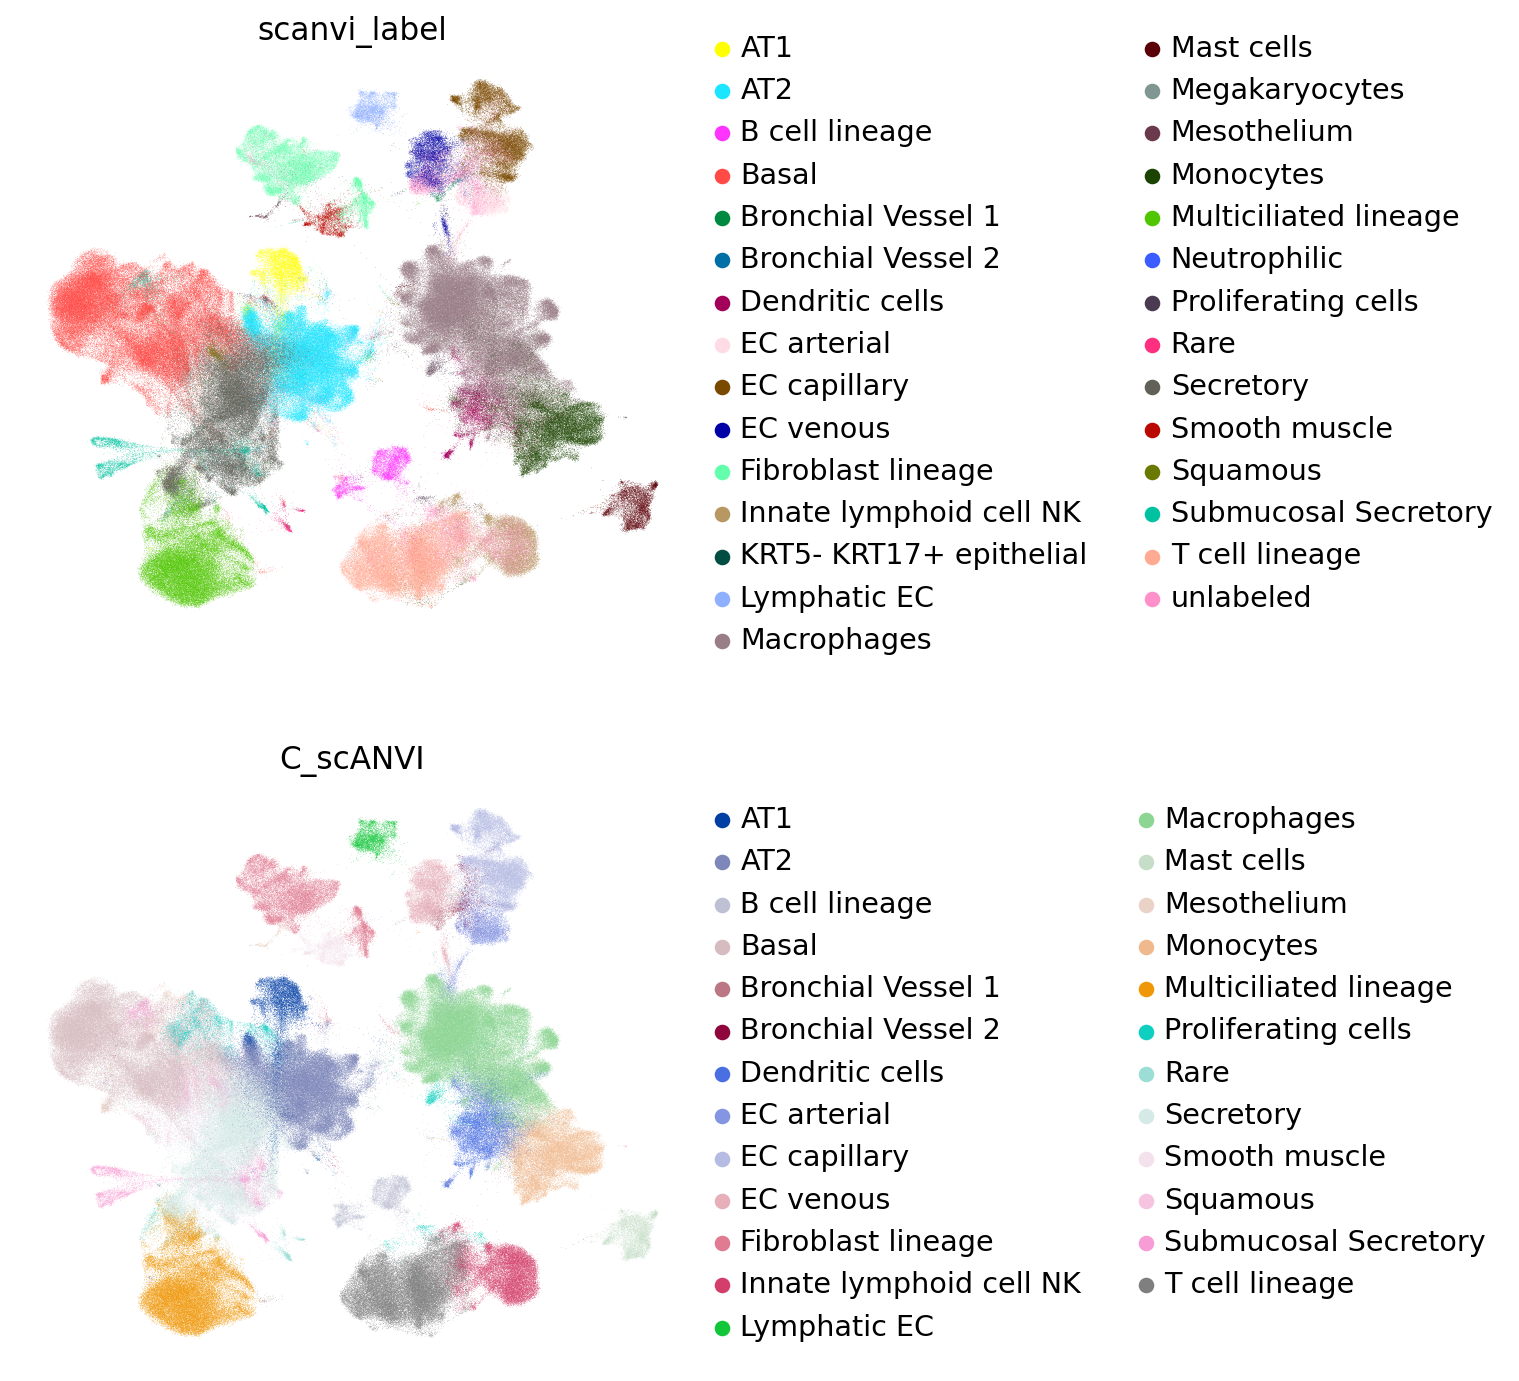

In [44]:
sc.pl.umap(source_adata, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

Create and plot a confusion matrix.

In [45]:
df = source_adata.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

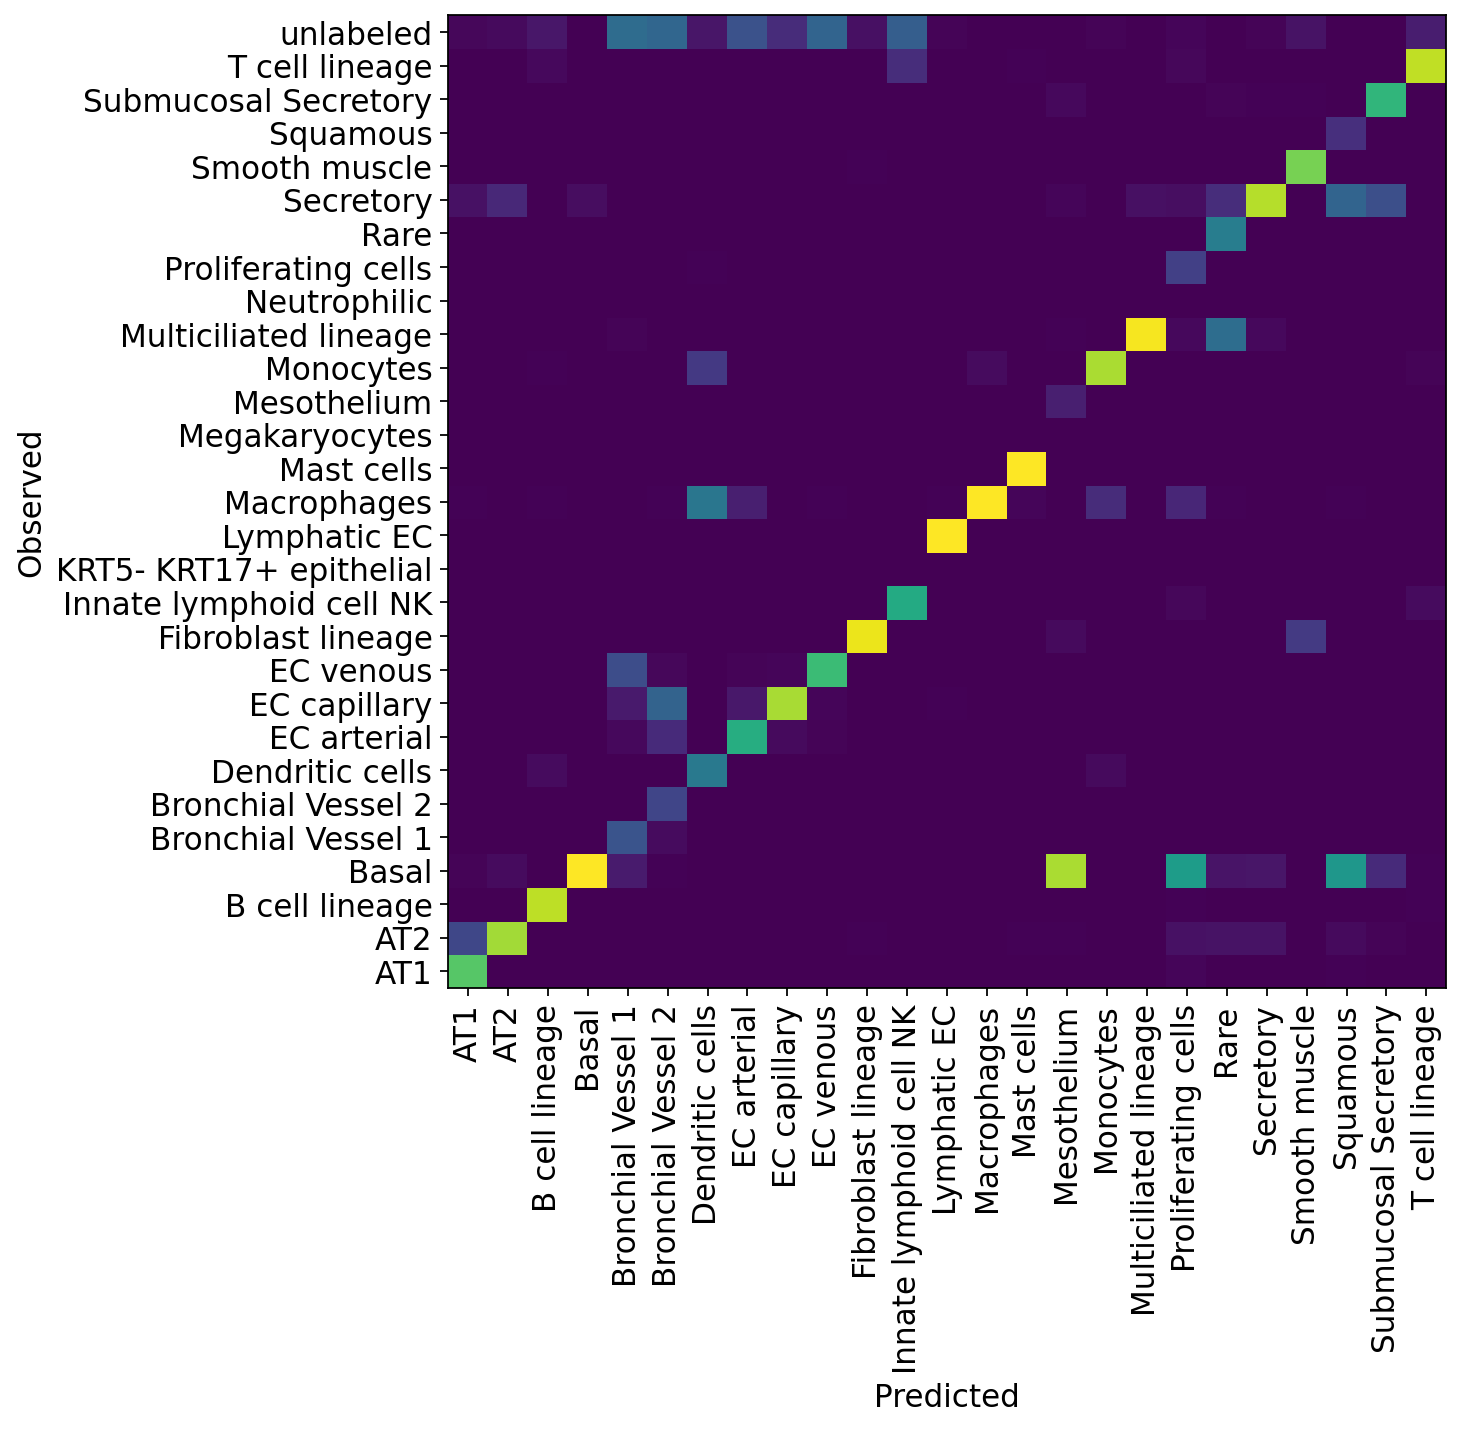

In [46]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

## Store results:

In [58]:
reference_latent = sc.AnnData(scANVI_model.get_latent_representation())
reference_latent.obs.index = source_adata.obs.index

In [59]:
reference_latent.write("/storage/groups/ml01/workspace/jan.domke/Data/scANVI_embedding.h5ad")

In [60]:
source_adata.write("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")

In [47]:
sc.logging.print_versions()

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.6
scanpy      1.8.1
sinfo       0.3.4
-----
PIL                         8.3.1
absl                        NA
anyio                       NA
attr                        21.2.0
babel                       2.9.1
backcall                    0.2.0
beta_ufunc                  NA
binom_ufunc                 NA
bottleneck                  1.3.2
brotli                      NA
certifi                     2021.10.08
cffi                        1.14.6
chardet                     4.0.0
charset_normali